In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
compute_device = torch.device("cuda:0" if (torch.cuda.is_available()) else "cpu")
compute_device

device(type='cpu')

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
from torchvision import transforms
from torchvision.utils import  make_grid
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
batch_sz = 16
img_dim = 64

# Création du Dataset
image_dataset = dset.ImageFolder(
    root='/content/drive/MyDrive/GAN/Data/datasets/',
    transform=transforms.Compose([
        transforms.Resize(img_dim),
        transforms.CenterCrop(img_dim),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]))

In [ ]:
len(image_dataset)

2048

Les deux classes

In [ ]:
data_classes = image_dataset.classes
data_classes

['Real_images', 'bad_fake_images']

In [ ]:
training_data, testing_data = torch.utils.data.random_split(image_dataset, [1548, 500])

In [ ]:
train_loader = torch.utils.data.DataLoader(
    training_data, batch_size=batch_sz,
    shuffle=True, num_workers=2
)
test_loader = torch.utils.data.DataLoader(
    testing_data, batch_size=batch_sz,
    shuffle=False, num_workers=2
)

In [ ]:
data_iter = iter(train_loader)
imgs, lbls = next(data_iter)
imgs.shape

torch.Size([16, 3, 64, 64])

Visualisation des images


In [ ]:
def show_image(img):
    img = img / 2 + 0.5
    img = img.permute(1, 2, 0)
    np_img = img.numpy()

    plt.imshow(np_img)
    plt.xticks([])
    plt.yticks([])
    plt.show()

print(' '.join( f"  Bad".center(7) if "bad" in f'{data_classes[lbls[j]]:5s}' else "   Real" for j in range(8)))
show_image(make_grid(imgs, 8))

print(' '.join( f"  Bad".center(7) if "bad" in f'{data_classes[lbls[j]]:5s}' else "   Real" for j in range(8,16)))

In [ ]:
num_channels = 3
feature_size = 64
learning_rate = 0.0002

In [ ]:
def init_weights(model):
    class_name = model.__class__.__name__

    if class_name.find('Conv') != -1:
        nn.init.normal_(model.weight.data, 0.0, 0.02)

    elif class_name.find('BatchNorm') != -1:
        nn.init.normal_(model.weight.data, 1.0, 0.02)
        nn.init.constant_(model.bias.data, 0)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(
                in_channels=num_channels,
                out_channels=feature_size,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                in_channels=feature_size,
                out_channels=feature_size * 2,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(feature_size * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                in_channels=feature_size * 2,
                out_channels=feature_size * 4,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(feature_size * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                in_channels=feature_size * 4,
                out_channels=feature_size * 8,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(feature_size * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                in_channels=feature_size * 8,
                out_channels=1,
                kernel_size=4,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

net_classifier = Discriminator().to(compute_device)
net_classifier.apply(init_weights)
print(net_classifier)

Discriminator(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)


In [ ]:
loss_function = nn.BCELoss()
optim_handler = optim.Adam(net_classifier.parameters(), lr=learning_rate, betas=(0.5, 0.999))

Lancement de l'étape du Train  

In [ ]:
for epoch in range(2):
    total_loss = 0.0
    for step, batch_data in enumerate(train_loader, 0):
        input_imgs, input_labels = batch_data
        input_imgs = input_imgs.to(compute_device)
        input_labels = input_labels.to(compute_device)

        optim_handler.zero_grad()

        preds = net_classifier(input_imgs)

        batch_loss = loss_function(preds.flatten(), input_labels.float())
        batch_loss.backward()

        optim_handler.step()

        total_loss += batch_loss.item()

        if step % 20 == 0:
            print(f'[Epoch: {epoch + 1}, Step: {step + 1:5d}] loss: {total_loss / 20:.3f}')
            total_loss = 0.0
print('Training Complete')

[Epoch: 1, Step:     1] loss: 0.060
[Epoch: 1, Step:    21] loss: 0.119
[Epoch: 1, Step:    41] loss: 0.006
[Epoch: 1, Step:    61] loss: 0.003
[Epoch: 1, Step:    81] loss: 0.005
[Epoch: 2, Step:     1] loss: 0.000
[Epoch: 2, Step:    21] loss: 0.004
[Epoch: 2, Step:    41] loss: 0.001
[Epoch: 2, Step:    61] loss: 0.000
[Epoch: 2, Step:    81] loss: 0.000
Training Complete


GroundTruth: 
   Real    Bad     Bad     Real    Real    Bad     Real    Bad 


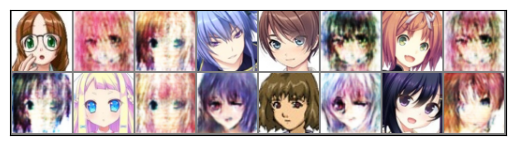

   Bad     Real    Bad     Bad     Real    Bad     Real    Bad 


In [ ]:
data_iter = iter(test_loader)
test_imgs, test_labels = next(data_iter)
print('GroundTruth: ')

print(' '.join( f"  Bad".center(7) if "bad" in f'{data_classes[test_labels[j]]:5s}' else "   Real" for j in range(8)))
show_image(make_grid(test_imgs, 8))
print(' '.join( f"  Bad".center(7) if "bad" in f'{data_classes[test_labels[j]]:5s}' else "   Real" for j in range(8,16)))

Predicted: 
   Real    Bad     Bad     Real    Real    Bad     Real    Bad 


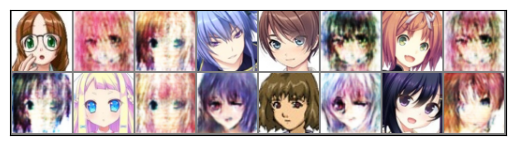

   Bad     Real    Bad     Bad     Real    Bad     Real    Bad 


In [ ]:
preds_test = net_classifier(test_imgs.to(compute_device))
predicted_vals = torch.round(preds_test.flatten())
print('Predicted: ')
print(' '.join( f"  Bad".center(7) if "bad" in f'{data_classes[predicted_vals.long()[j]]:5s}' else "   Real" for j in range(8)))
show_image(make_grid(test_imgs, 8))
print(' '.join( f"  Bad".center(7) if "bad" in f'{data_classes[predicted_vals.long()[j]]:5s}' else "   Real" for j in range(8,16)))



In [ ]:

correct_predictions = 0
total_samples = 0
with torch.no_grad():
    for batch in test_loader:
        test_imgs, test_labels = batch
        test_imgs = test_imgs.to(compute_device)
        test_labels = test_labels.to(compute_device)

        batch_preds = net_classifier(test_imgs)

        predicted_labels = torch.round(batch_preds.flatten()).long()

        total_samples += test_labels.size(0)
        correct_predictions += (predicted_labels == test_labels).sum().item()

print(f'Accuracy =: {100 * correct_predictions // total_samples} %')

Accuracy =: 100 %


In [ ]:
class_correct = {cls: 0 for cls in data_classes}
class_total = {cls: 0 for cls in data_classes}

with torch.no_grad():
    for batch in test_loader:
        test_imgs, test_labels = batch

        test_imgs = test_imgs.to(compute_device)
        test_labels = test_labels.to(compute_device)

        batch_preds = net_classifier(test_imgs)

        class_preds = torch.round(batch_preds.flatten()).long()

        for actual_label, pred_label in zip(test_labels, class_preds):
            if actual_label == pred_label:
                class_correct[data_classes[actual_label]] += 1
            class_total[data_classes[actual_label]] += 1

for cls_name, correct_count in class_correct.items():
    acc = 100 * float(correct_count) / class_total[cls_name]
    print(f'Accuracy for class: {cls_name:5s} is {acc:.1f} %')


Accuracy for class: Real_images is 100.0 %
Accuracy for class: bad_fake_images is 100.0 %
